# Experimento 17 — YOLO11n com hiperparâmetros otimizados pelo Optuna

- Autor: Clésio Gonçalves
- Criado em: 18 nov. 2026

**Objetivo:** fazer a busca de hiperparâmetros com o Optuna **diretamente no YOLO11n**, em vez de reaproveitar a do YOLO11l (exp16: mAP50 0,509 ± 0,109). Base: exp08 (YOLO11n, macrófago mascarado de preto, batch 16; mAP50 0,485 ± 0,109).

**Perguntas:** (1) uma busca feita no próprio nano encontra parâmetros melhores que os herdados do YOLO11l? (2) com o nano ~4× mais rápido por época, uma busca maior (mais tentativas, mais épocas) compensa?

**Dataset:** recortes com o macrófago pintado de preto, o mesmo dos exp08, 09, 15 e 16. A máscara com a cor do fundo (exp13) deu o mesmo resultado (0,488 contra 0,485); manter o preto deixa o exp17 diferente do exp16 só pela busca e do exp15 só pelo modelo.

**Protocolo (otimização aninhada, sem vazamento):** igual ao exp15. Cada fold tem um estudo próprio que só olha a lâmina de validação do fold. Depois cada fold é treinado com os seus melhores parâmetros (150 épocas, patience 40) e avaliado no teste.

**Busca:** 16 tentativas por fold × 20 épocas (o exp15 usou 8 × 15). As 2 primeiras tentativas de cada fold são fixas: a configuração do exp08 e os parâmetros que o exp15 achou para esse fold. As faixas de `lr0` e `degrees` foram ampliadas, porque no exp15 a busca parou nos limites delas.

| | |
|---|---|
| **Dataset** | `02_datasets_derivados/03_recortes_512_sem_macrofago/` |
| **Modelo** | `yolo11n.pt` (2,6M parâmetros), batch 16, imgsz 512 |
| **Busca** | 16 tentativas × 20 épocas por fold, TPE, MedianPruner; tentativas 1 e 2 = exp08 e exp15 |
| **Métrica da busca** | maior mAP50 na lâmina de validação do fold |
| **Estudos** | `optuna/estudos.db` (SQLite; continua de onde parou) |
| **Bases** | exp08 (mesmo modelo, à mão), exp16 (mesmo modelo, parâmetros do exp15) |

## Resultado (18 nov. 2026, 1h13)

| | Hiperparâmetros | Precisão | Recall | mAP50 | mAP50-95 |
|---|---|---|---|---|---|
| **exp17** | busca no YOLO11n | 0,510 ± 0,132 | 0,565 ± 0,085 | **0,495 ± 0,144** | 0,190 ± 0,056 |
| exp16 | herdados do exp15 | 0,525 ± 0,110 | 0,566 ± 0,055 | 0,509 ± 0,109 | 0,196 ± 0,039 |
| exp08 | à mão | 0,508 ± 0,102 | 0,547 ± 0,074 | 0,485 ± 0,109 | 0,184 ± 0,039 |

- A busca no nano não superou os parâmetros herdados do YOLO11l. Melhorou a validação nos 6 folds, mas não o teste: com uma lâmina de validação por fold, ela se ajusta a essa lâmina (pior caso: fold 6, validação leish_1, 0,289 contra 0,403).
- As escolhas se espalharam e não repetiram os padrões do exp15. Detalhes no `README.html`.

## Utilização da GPU

In [1]:
!nvidia-smi

Wed Nov 18 14:55:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.99.02              Driver Version: 595.99.02      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5070 Ti     Off |   00000000:01:00.0  On |                  N/A |
|  0%   47C    P1             51W /  300W |    1327MiB /  16303MiB |      4%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"


# Importações e parâmetros gerais

In [3]:
import shutil
import yaml
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
from pathlib import Path
from PIL import Image

import torch
from ultralytics import YOLO

import warnings
warnings.filterwarnings('ignore')

# Bloqueia logs de C++ (INFO e WARNING)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_MLIR_ENABLE_MLIR_HAL_TARGET_ EXECUTABLE_DUMP_PATH'] = ''
os.environ['MLIR_CRASH_REPRODUCER_DIRECTORY'] = ''


In [4]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Clésio Gonçalves" --iversions
!python --version
!conda -V


Author: Clésio Gonçalves

PIL        : 12.0.0
cv2        : 4.13.0
matplotlib : 3.10.6
numpy      : 2.3.5
pandas     : 2.3.3
torch      : 2.12.1
ultralytics: 8.4.75
yaml       : 6.0.3

Python 3.13.9


conda 26.1.1


In [5]:
torch.cuda.is_available()

True

## Parâmetros do sistema

In [6]:
# Diretório raiz
diretorio_raiz = Path("/mnt/arquivos/Doutorado")


## Estrutura do Dataset

- 8 lâminas anotadas no formato YOLO; recortes 512×512 centrados em macrófagos infectados: recortes 512×512 com a bbox do macrófago pintada de preto (mesmo dataset do exp08).
- Classes do `obj.names` (mantido igual ao original): `0 Non-macrophages`, `1 macrophage` (ausente: região apagada), `2 leishmania` (**alvo**: fora do macrófago), `3 inside-macrophage` (ausente).
- Só a classe `leishmania` é usada, remapeada para o índice `0` (detector de classe única).

![Divisão dos folds por lâmina](../01_preprocessamento/divisao_folds_por_lamina.jpeg)

## Parâmetros do experimento

In [7]:
# Diretório deste experimento (na raiz do projeto)
diretorio_experimento = os.path.join(diretorio_raiz, "05_novos_experimentos", "exp17_yolo11n_optuna")

# Dataset: recortes 512×512 com a bbox do macrófago pintada de preto (mesmo dataset do exp08)
# (gerado por 01_preprocessamento/03_mascarar_macrofago_nos_recortes.ipynb)
diretorio_recortes = os.path.join(diretorio_raiz, "02_datasets_derivados", "03_recortes_512_sem_macrofago")

# Tamanho de treino/inferência = tamanho original do recorte, sem upscaling
tamanho_imagem = 512
extensao = '.png'

# Classes do dataset de recortes (mesma ordem do obj.names)
caminho_obj_names = os.path.join(diretorio_recortes, "obj.names")
with open(caminho_obj_names) as f:
    classes_originais = [linha.strip() for linha in f]

# Apenas leishmania FORA do macrófago é a classe de interesse (single-class detector)
nome_classe_interesse = 'leishmania'
indice_classe_interesse = classes_originais.index(nome_classe_interesse)
print(f"Classes originais: {classes_originais}")
print(f"Índice de '{nome_classe_interesse}' (classe de interesse): {indice_classe_interesse}")

# Estrutura YOLO por fold e runs ficam dentro da pasta do experimento
diretorio_yolo_folds = os.path.join(diretorio_experimento, "folds_yolo")
diretorio_runs = os.path.join(diretorio_experimento, "runs")
os.makedirs(diretorio_yolo_folds, exist_ok=True)
os.makedirs(diretorio_runs, exist_ok=True)

# Pesos pré-treinados do YOLO11-nano (cópia local; baixados pela Ultralytics se faltarem)
caminho_pesos_pretreinados = os.path.join(diretorio_experimento, 'yolo11n.pt')
if not os.path.isfile(caminho_pesos_pretreinados):
    caminho_pesos_pretreinados = 'yolo11n.pt'

tamanho_batch = 16

# Hiperparâmetros de treinamento: idênticos ao exp08 (os 7 otimizados pelo Optuna são substituídos por fold)
parametros_treino = dict(
    epochs=150,
    patience=40,
    imgsz=tamanho_imagem,
    batch=tamanho_batch,
    device=0,
    seed=42,
    workers=8,
    cos_lr=True,
    single_cls=True,
    verbose=False,
    optimizer='AdamW',
    lr0=0.0005,
    lrf=0.01,
    # aumento de dados: jitter de cor (imagens em RGB), rotação, flip vertical (sem orientação
    # canônica em microscopia) e mixup; mosaico, flip horizontal, translação e escala seguem o padrão.
    hsv_h=0.03,
    hsv_s=0.9,
    hsv_v=0.6,
    degrees=15.0,
    flipud=0.5,
    mixup=0.1,
)

Classes originais: ['Non-macrophages', 'macrophage', 'leishmania', 'inside-macrophage']
Índice de 'leishmania' (classe de interesse): 2


## Definição dos 6 folds (idêntica aos experimentos anteriores, para comparação direta)

In [8]:
folds = [
    {'fold': 1, 'treino': ['leish_1', 'leish_2', 'leish_7', 'leish_8', 'leish_9'], 'validacao': ['leish_4'], 'teste': ['leish_3', 'leish_5']},
    {'fold': 2, 'treino': ['leish_1', 'leish_3', 'leish_4', 'leish_5', 'leish_9'], 'validacao': ['leish_8'], 'teste': ['leish_2', 'leish_7']},
    {'fold': 3, 'treino': ['leish_2', 'leish_3', 'leish_4', 'leish_5', 'leish_7'], 'validacao': ['leish_9'], 'teste': ['leish_1', 'leish_8']},
    {'fold': 4, 'treino': ['leish_1', 'leish_2', 'leish_3', 'leish_5', 'leish_8'], 'validacao': ['leish_7'], 'teste': ['leish_4', 'leish_9']},
    {'fold': 5, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_8', 'leish_9'], 'validacao': ['leish_2'], 'teste': ['leish_1', 'leish_7']},
    {'fold': 6, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_7', 'leish_9'], 'validacao': ['leish_1'], 'teste': ['leish_2', 'leish_8']},
]

pd.DataFrame(folds).set_index('fold')


,treino,validacao,teste
fold,,,
1,"[leish_1, leish_2, leish_7, leish_8, leish_9]",[leish_4],"[leish_3, leish_5]"
2,"[leish_1, leish_3, leish_4, leish_5, leish_9]",[leish_8],"[leish_2, leish_7]"
3,"[leish_2, leish_3, leish_4, leish_5, leish_7]",[leish_9],"[leish_1, leish_8]"
4,"[leish_1, leish_2, leish_3, leish_5, leish_8]",[leish_7],"[leish_4, leish_9]"
5,"[leish_3, leish_4, leish_5, leish_8, leish_9]",[leish_2],"[leish_1, leish_7]"
6,"[leish_3, leish_4, leish_5, leish_7, leish_9]",[leish_1],"[leish_2, leish_8]"


## Construção da estrutura de dataset YOLO para cada fold

In [9]:
# Filtra as anotações de um .txt YOLO, mantendo só a classe de interesse e remapeando-a para o índice 0
def remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse):
    linhas_novas = []
    if os.path.isfile(txt_origem):
        with open(txt_origem) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                partes = linha.split()
                if int(partes[0]) == indice_classe_interesse:
                    linhas_novas.append("0 " + " ".join(partes[1:]))
    return linhas_novas


# Cria link simbólico de uma imagem e grava o .txt remapeado (classe única) na pasta de destino
def linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse):
    nome_base = os.path.splitext(arquivo)[0]

    img_origem = os.path.join(pasta_origem, arquivo)
    img_destino = os.path.join(pasta_img_destino, arquivo)
    if not os.path.exists(img_destino):
        os.symlink(img_origem, img_destino)

    txt_origem = os.path.join(pasta_origem, f"{nome_base}.txt")
    linhas = remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse)
    with open(os.path.join(pasta_lbl_destino, f"{nome_base}.txt"), 'w') as f:
        f.write("\n".join(linhas))
        if linhas:
            f.write("\n")


# Monta a estrutura YOLO (images/labels) de um fold: treino, validação, teste (agregado) e teste por lâmina
def monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao):
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{fold['fold']}")
    if os.path.isdir(diretorio_fold):
        shutil.rmtree(diretorio_fold)

    for papel, laminas in [('train', fold['treino']), ('val', fold['validacao']), ('test', fold['teste'])]:
        pasta_img_destino = os.path.join(diretorio_fold, 'images', papel)
        pasta_lbl_destino = os.path.join(diretorio_fold, 'labels', papel)
        os.makedirs(pasta_img_destino, exist_ok=True)
        os.makedirs(pasta_lbl_destino, exist_ok=True)

        for lamina in laminas:
            pasta_origem = os.path.join(diretorio_recortes, lamina)

            if papel == 'test':
                # subpasta individual da lâmina (usada no diagnóstico por lâmina do conjunto de teste)
                pasta_img_lamina = os.path.join(diretorio_fold, 'images', 'test_lamina', lamina)
                pasta_lbl_lamina = os.path.join(diretorio_fold, 'labels', 'test_lamina', lamina)
                os.makedirs(pasta_img_lamina, exist_ok=True)
                os.makedirs(pasta_lbl_lamina, exist_ok=True)

            for arquivo in sorted(os.listdir(pasta_origem)):
                if not arquivo.endswith(extensao):
                    continue
                linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse)
                if papel == 'test':
                    linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_lamina, pasta_lbl_lamina, indice_classe_interesse)

    return diretorio_fold


for fold in folds:
    diretorio_fold = monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao)
    n_train = len(os.listdir(os.path.join(diretorio_fold, 'images', 'train')))
    n_val = len(os.listdir(os.path.join(diretorio_fold, 'images', 'val')))
    n_test = len(os.listdir(os.path.join(diretorio_fold, 'images', 'test')))
    print(f"Fold {fold['fold']}: treino={n_train} | validação={n_val} | teste={n_test}")


Fold 1: treino=1064 | validação=126 | teste=378


Fold 2: treino=808 | validação=353 | teste=407


Fold 3: treino=911 | validação=208 | teste=449


Fold 4: treino=954 | validação=280 | teste=334


Fold 5: treino=1065 | validação=127 | teste=376


Fold 6: treino=992 | validação=96 | teste=480


## Geração dos arquivos `data.yaml` por fold

In [10]:
# Grava o data.yaml de um fold. Se 'test_split' for informado, aponta o "test" para uma subpasta específica (lâmina única)
def gera_data_yaml(diretorio_fold, nome_classe, caminho_yaml, test_split='test'):
    conteudo = {
        'path': str(diretorio_fold),
        'train': 'images/train',
        'val': 'images/val',
        'test': f'images/{test_split}',
        'nc': 1,
        'names': {0: nome_classe},
    }
    with open(caminho_yaml, 'w') as f:
        yaml.safe_dump(conteudo, f, sort_keys=False, allow_unicode=True)
    return caminho_yaml


caminhos_yaml = {}        # data.yaml agregado (teste = todas as lâminas do fold)
caminhos_yaml_lamina = {} # data.yaml por lâmina de teste, usado no diagnóstico

for fold in folds:
    n = fold['fold']
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{n}")

    caminhos_yaml[n] = gera_data_yaml(
        diretorio_fold, nome_classe_interesse,
        os.path.join(diretorio_fold, 'data.yaml'),
    )

    for lamina in fold['teste']:
        caminhos_yaml_lamina[(n, lamina)] = gera_data_yaml(
            diretorio_fold, nome_classe_interesse,
            os.path.join(diretorio_fold, f'data_test_{lamina}.yaml'),
            test_split=f'test_lamina/{lamina}',
        )

print(f"{len(caminhos_yaml)} data.yaml agregados e {len(caminhos_yaml_lamina)} data.yaml por lâmina de teste gerados.")


6 data.yaml agregados e 12 data.yaml por lâmina de teste gerados.


## Otimização de hiperparâmetros com o Optuna no YOLO11n (fator testado neste experimento)

**Como funciona:** o Optuna propõe uma combinação de hiperparâmetros (uma *tentativa*), treina, mede o mAP50 na validação e usa o histórico para escolher a próxima. O amostrador **TPE** sorteia as próximas tentativas perto das que foram boas. O **MedianPruner** interrompe no meio uma tentativa cujo mAP50 está abaixo da mediana das anteriores na mesma época.

**Por fold, sem vazamento:** cada fold tem um estudo próprio, que treina nas 5 lâminas de treino e mede na lâmina de validação. As 2 lâminas de teste ficam fora da busca.

**Orçamento:** 16 tentativas de 20 épocas por fold e 7 hiperparâmetros: taxa de aprendizado, regularização, cor, rotação, escala e mixup. Os demais ficam como no exp08. O YOLO11n é ~4× mais rápido por época que o YOLO11l, o que permite uma busca maior que a do exp15. Tentativas curtas favorecem configurações que aprendem rápido. É uma limitação conhecida da busca com pouco orçamento.

**Ponto de partida:** a 1ª tentativa de cada estudo é a configuração do exp08 e a 2ª são os parâmetros que o exp15 achou para o mesmo fold. O Optuna só troca essas configurações se encontrar algo melhor na validação.

**Faixas ampliadas:** `lr0` de 2e-5 a 2e-3 e `degrees` de 0 a 45, porque no exp15 a busca parou no limite inferior de `lr0` (1e-4) e no superior de `degrees` (30).

In [11]:
import gc
import json
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner

optuna.logging.set_verbosity(optuna.logging.WARNING)

n_tentativas = 16        # tentativas por fold
epocas_tentativa = 20    # épocas de cada tentativa (treino curto)

diretorio_optuna = os.path.join(diretorio_experimento, 'optuna')
os.makedirs(diretorio_optuna, exist_ok=True)
armazenamento = f"sqlite:///{os.path.join(diretorio_optuna, 'estudos.db')}"

# Configuração do exp08 para os 7 hiperparâmetros buscados: 1ª tentativa de todos os estudos
parametros_exp08 = dict(lr0=0.0005, weight_decay=0.0005, hsv_s=0.9, hsv_v=0.6, degrees=15.0, scale=0.5, mixup=0.1)

# Parâmetros que o Optuna achou no exp15 (YOLO11l) para cada fold: 2ª tentativa do estudo do mesmo fold
caminho_params_exp15 = os.path.join(diretorio_raiz, '05_novos_experimentos', 'exp15_yolo11l_optuna', 'optuna', 'melhores_parametros.json')
with open(caminho_params_exp15) as f:
    parametros_exp15 = {int(k): v for k, v in json.load(f).items()}


# Espaço de busca: os 7 hiperparâmetros do exp15, com lr0 e degrees ampliados (no exp15 a busca parou nos limites)
def espaco_busca(tentativa):
    return dict(
        lr0=tentativa.suggest_float('lr0', 2e-5, 2e-3, log=True),               # taxa de aprendizado inicial
        weight_decay=tentativa.suggest_float('weight_decay', 1e-5, 1e-3, log=True),  # regularização dos pesos
        hsv_s=tentativa.suggest_float('hsv_s', 0.2, 0.9),                       # jitter de saturação
        hsv_v=tentativa.suggest_float('hsv_v', 0.2, 0.7),                       # jitter de brilho
        degrees=tentativa.suggest_float('degrees', 0.0, 45.0),                  # rotação
        scale=tentativa.suggest_float('scale', 0.2, 0.6),                       # variação de escala
        mixup=tentativa.suggest_float('mixup', 0.0, 0.3),                       # mixup
    )


# Uma tentativa: treino curto no fold n, medido na lâmina de validação do fold
def objetivo(tentativa, n_fold):
    params = espaco_busca(tentativa)
    historico = []

    def reporta_e_poda(trainer):
        valor = float(trainer.metrics.get('metrics/mAP50(B)', 0.0))
        historico.append(valor)
        tentativa.report(valor, trainer.epoch)
        if tentativa.should_prune():
            raise optuna.TrialPruned()

    modelo = YOLO(caminho_pesos_pretreinados)
    modelo.add_callback('on_fit_epoch_end', reporta_e_poda)
    cfg = {**parametros_treino, **params,
           'epochs': epocas_tentativa, 'patience': epocas_tentativa,
           'save': False, 'plots': False, 'verbose': False,
           'project': os.path.join(diretorio_optuna, f'fold_{n_fold}'),
           'name': f'tentativa_{tentativa.number}', 'exist_ok': True}
    try:
        modelo.train(data=caminhos_yaml[n_fold], **cfg)
    finally:
        del modelo
        gc.collect()
        torch.cuda.empty_cache()
    return max(historico) if historico else 0.0

In [12]:
melhores_params = {}
estudos = {}

for fold in folds:
    n = fold['fold']
    estudo = optuna.create_study(
        study_name=f'fold_{n}', storage=armazenamento, direction='maximize', load_if_exists=True,
        sampler=TPESampler(seed=42 + n, n_startup_trials=5),
        pruner=MedianPruner(n_startup_trials=4, n_warmup_steps=6))
    if len(estudo.trials) == 0:
        estudo.enqueue_trial(parametros_exp08)
        estudo.enqueue_trial(parametros_exp15[n])

    feitas = sum(t.state in (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED) for t in estudo.trials)
    faltam = n_tentativas - feitas
    if faltam > 0:
        print(f"Fold {n}: {feitas} tentativas já feitas, rodando mais {faltam} (validação: {fold['validacao'][0]})")
        estudo.optimize(lambda t: objetivo(t, n), n_trials=faltam, gc_after_trial=True)
    else:
        print(f"Fold {n}: estudo completo ({feitas} tentativas). Busca ignorada.")

    estudos[n] = estudo
    melhores_params[n] = estudo.best_params
    print(f"Fold {n}: melhor mAP50 na validação = {estudo.best_value:.4f} (tentativa {estudo.best_trial.number}); "
          f"exp08 = {estudo.trials[0].value:.4f}; parâmetros do exp15 = {estudo.trials[1].value:.4f}")

with open(os.path.join(diretorio_optuna, 'melhores_parametros.json'), 'w') as f:
    json.dump(melhores_params, f, indent=2)

Fold 1: 0 tentativas já feitas, rodando mais 16 (validação: leish_4)
New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15819MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/mnt/arquivos/Doutorado/05_novos_experimentos/exp17_yolo11n_optuna/folds_yolo/fold_1/data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.03, hsv_s=0.9, hsv_v=0.6, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=/mnt/arquivos/Doutorado/05_novos_experimentos/exp17_yolo11n_optuna/yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=tentativa_0, nbs=64, nms=False, opset=None, optimize=Fal

Overriding class names with single class.


Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


... (32,861 outputs left out)

      11/20       1.9G      1.914      1.559      1.093        129        512: 100% ━━━━━━━━━━━━ 62/62 31.9it/s 1.9s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 26.3it/s 0.1s

                   all         96        831      0.618      0.528      0.536      0.212


Fold 6: melhor mAP50 na validação = 0.5923 (tentativa 13); exp08 = 0.5507; parâmetros do exp15 = 0.5614


In [13]:
# Resumo da busca: tentativas, interrompidas e ganho na validação sobre as configurações do exp08 e do exp15
linhas = []
for n, estudo in estudos.items():
    linhas.append({'fold': n,
                   'lâmina de validação': folds[n - 1]['validacao'][0],
                   'tentativas': len(estudo.trials),
                   'interrompidas (poda)': sum(t.state == optuna.trial.TrialState.PRUNED for t in estudo.trials),
                   'mAP50 val. exp08': round(estudo.trials[0].value, 4),
                   'mAP50 val. params exp15': round(estudo.trials[1].value or float('nan'), 4),
                   'mAP50 val. melhor': round(estudo.best_value, 4),
                   'melhor tentativa': estudo.best_trial.number})
pd.DataFrame(linhas).set_index('fold')

,lâmina de validação,tentativas,interrompidas (poda),mAP50 val. exp08,mAP50 val. params exp15,mAP50 val. melhor,melhor tentativa
fold,,,,,,,
1,leish_4,16,7,0.2080,0.2321,0.2511,15
2,leish_8,16,9,0.3398,0.3506,0.3852,9
3,leish_9,16,5,0.5901,0.5890,0.6344,8
4,leish_7,16,8,0.6425,0.6676,0.6822,13
5,leish_2,16,7,0.4009,0.4125,0.4491,5
6,leish_1,16,8,0.5507,0.5614,0.5923,13


In [14]:
# Melhores hiperparâmetros de cada fold, ao lado da configuração do exp08
tabela_params = pd.DataFrame(melhores_params).T
tabela_params.index.name = 'fold'
tabela_params.loc['exp08'] = parametros_exp08
tabela_params.round(5)

,lr0,weight_decay,hsv_s,hsv_v,degrees,scale,mixup
fold,,,,,,,
1,0.00041,0.00033,0.56203,0.34958,8.52917,0.38249,0.16539
2,0.00033,0.00004,0.67331,0.49568,0.70910,0.21144,0.07657
3,0.00012,0.00047,0.44144,0.37932,6.84287,0.29333,0.25733
4,0.00086,0.00012,0.27620,0.50670,28.05064,0.31289,0.23364
5,0.00136,0.00015,0.46765,0.20370,0.51446,0.20006,0.00013
6,0.00112,0.00029,0.74926,0.32864,2.41510,0.28247,0.29902
exp08,0.00050,0.00050,0.90000,0.60000,15.00000,0.50000,0.10000


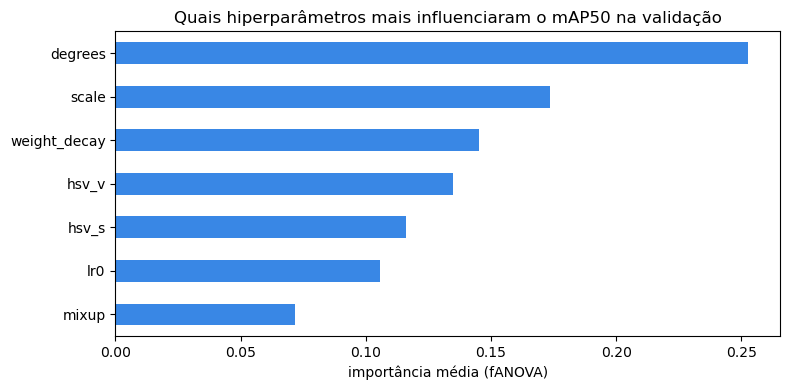

In [15]:
%matplotlib inline
# Importância de cada hiperparâmetro (fANOVA do Optuna), média entre os 6 estudos
importancias = []
for n, estudo in estudos.items():
    try:
        importancias.append(pd.Series(optuna.importance.get_param_importances(estudo), name=n))
    except Exception as erro:
        print(f"Fold {n}: importância não calculada ({erro})")
if importancias:
    imp = pd.concat(importancias, axis=1).fillna(0).mean(axis=1).sort_values()
    ax = imp.plot.barh(figsize=(8, 4), color='#3987e5')
    ax.set_xlabel('importância média (fANOVA)')
    ax.set_title('Quais hiperparâmetros mais influenciaram o mAP50 na validação')
    plt.tight_layout()
    plt.savefig(os.path.join(diretorio_experimento, 'figuras', 'importancia_hiperparametros.png'), dpi=110)
    plt.show()

## Treinamento final dos 6 folds (YOLO11n, batch 16) com os hiperparâmetros do Optuna

Cada fold é treinado do zero com os **seus** melhores hiperparâmetros (`melhores_params[n]`), no mesmo regime do exp08: 150 épocas, patience 40, batch 16. Se o `best.pt` de um fold já existir **e** existir `fold_N/concluido.txt`, o fold é pulado.

In [16]:
caminhos_best = {}

for fold in folds:
    n = fold['fold']
    nome_run = f"fold_{n}"
    caminho_best = os.path.join(diretorio_runs, nome_run, 'weights', 'best.pt')

    marcador = os.path.join(diretorio_runs, nome_run, 'concluido.txt')
    if os.path.isfile(caminho_best) and os.path.isfile(marcador):
        print(f"Fold {n}: pesos já existem em '{caminho_best}'. Treinamento ignorado.")
    else:
        modelo = YOLO(caminho_pesos_pretreinados)
        modelo.train(
            data=caminhos_yaml[n],
            project=diretorio_runs,
            name=nome_run,
            exist_ok=True,
            **{**parametros_treino, **melhores_params[n]},
        )
        with open(marcador, 'w') as f:
            f.write('treino concluído\n')
        print(f"Fold {n}: treinamento concluído. Pesos em '{caminho_best}'.")
        del modelo
        torch.cuda.empty_cache()

    caminhos_best[n] = caminho_best


New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15819MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/mnt/arquivos/Doutorado/05_novos_experimentos/exp17_yolo11n_optuna/folds_yolo/fold_1/data.yaml, degrees=8.52917497838184, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.03, hsv_s=0.562029564507028, hsv_v=0.3495848533814916, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0004061258601851733, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1653924592437283, mode=train, model=/mnt/arquivos/Doutorado/05_novos_experimentos/exp17_yolo11n_optuna/yolo11n.pt, momentum=0.937, mosaic=1.0, multi_

Overriding class names with single class.


Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


... (10,013 outputs left out)

                   all         96        831      0.619      0.609      0.607      0.269


Speed: 0.0ms preprocess, 0.3ms inference, 0.0ms loss, 0.5ms postprocess per image


Results saved to /mnt/arquivos/Doutorado/05_novos_experimentos/exp17_yolo11n_optuna/runs/fold_6


Fold 6: treinamento concluído. Pesos em '/mnt/arquivos/Doutorado/05_novos_experimentos/exp17_yolo11n_optuna/runs/fold_6/weights/best.pt'.


## Avaliação no conjunto de teste — agregada por fold

In [17]:
# Extrai as métricas de detecção relevantes de um resultado de model.val()
def extrai_metricas(resultado_val):
    rd = resultado_val.results_dict
    return {
        'precisao': rd.get('metrics/precision(B)', float('nan')),
        'recall': rd.get('metrics/recall(B)', float('nan')),
        'mAP50': rd.get('metrics/mAP50(B)', float('nan')),
        'mAP50-95': rd.get('metrics/mAP50-95(B)', float('nan')),
    }


linhas_metricas_fold = []

for fold in folds:
    n = fold['fold']
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminhos_yaml[n], split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['laminas_teste'] = ", ".join(fold['teste'])
    linhas_metricas_fold.append(metricas)

df_metricas_fold = pd.DataFrame(linhas_metricas_fold).set_index('fold')
df_metricas_fold = df_metricas_fold[['laminas_teste', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_fold


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15819MiB)


YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3657.4±566.6 MB/s, size: 219.2 KB)


val: Scanning /mnt/arquivos/Doutorado/05_novos_experimentos/exp17_yolo11n_optuna/folds_yolo/fold_1/labels/test... 378 images, 52 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 378/378 6.8Kit/s 0.1s

val: New cache created: /mnt/arquivos/Doutorado/05_novos_experimentos/exp17_yolo11n_optuna/folds_yolo/fold_1/labels/test.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 4% ──────────── 1/24 2.7it/s 0.1s<8.6s

... (68 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 43.9it/s 0.7s

                   all        480       1634      0.324      0.461      0.289       0.11


Speed: 0.1ms preprocess, 0.5ms inference, 0.0ms loss, 0.3ms postprocess per image


,laminas_teste,precisao,recall,mAP50,mAP50-95
fold,,,,,
1,"leish_3, leish_5",0.572386,0.599578,0.568180,0.195566
2,"leish_2, leish_7",0.604702,0.648547,0.609900,0.244226
3,"leish_1, leish_8",0.416796,0.462985,0.374103,0.145123
4,"leish_4, leish_9",0.463920,0.568465,0.469029,0.192271
5,"leish_1, leish_7",0.678755,0.647078,0.658194,0.253846
6,"leish_2, leish_8",0.323548,0.461444,0.288796,0.110382


In [18]:
# Média aritmética e desvio padrão de cada métrica entre os 6 folds
resumo_metricas = df_metricas_fold[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std']).T
resumo_metricas.columns = ['média', 'desvio_padrão']
resumo_metricas.round(4)


,média,desvio_padrão
precisao,0.5100,0.1318
recall,0.5647,0.0849
mAP50,0.4947,0.1435
mAP50-95,0.1902,0.0555


## Comparação com os experimentos anteriores

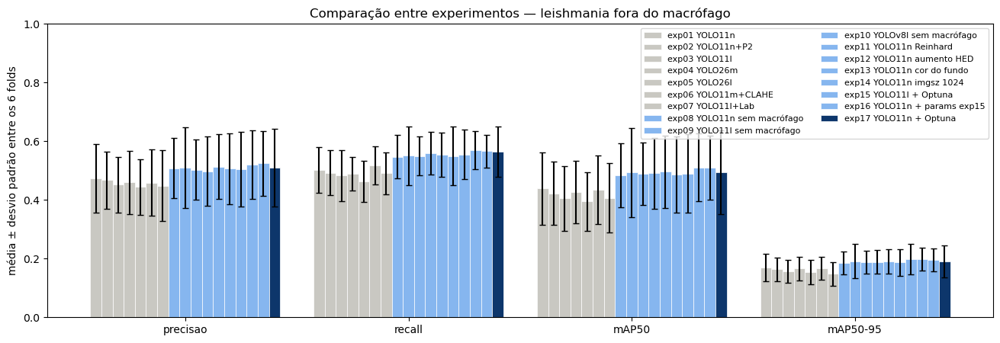

In [19]:
%matplotlib inline
# Médias e desvios padrão dos experimentos anteriores (numeração do resumo_experimentos.html).
# exp01-07: recortes com o macrófago visível; exp08-16: recortes com o macrófago mascarado.
# Bases diretas: exp08 (mesmo modelo, à mão) e exp16 (mesmo modelo, parâmetros do exp15).
anteriores = {
    'exp01 YOLO11n':               ((0.4735, 0.1164), (0.5012, 0.0780), (0.4391, 0.1229), (0.1695, 0.0457)),
    'exp02 YOLO11n+P2':            ((0.4672, 0.0981), (0.4922, 0.0763), (0.4226, 0.1083), (0.1640, 0.0405)),
    'exp03 YOLO11l':               ((0.4520, 0.0945), (0.4832, 0.0864), (0.4048, 0.1095), (0.1576, 0.0391)),
    'exp04 YOLO26m':               ((0.4595, 0.1079), (0.4894, 0.0567), (0.4272, 0.1068), (0.1659, 0.0396)),
    'exp05 YOLO26l':               ((0.4442, 0.0946), (0.4632, 0.0705), (0.3943, 0.1000), (0.1538, 0.0417)),
    'exp06 YOLO11m+CLAHE':         ((0.4581, 0.1132), (0.5170, 0.0652), (0.4345, 0.1175), (0.1670, 0.0391)),
    'exp07 YOLO11l+Lab':           ((0.4485, 0.1206), (0.4904, 0.0707), (0.4067, 0.1180), (0.1483, 0.0407)),
    'exp08 YOLO11n sem macrófago': ((0.5077, 0.1022), (0.5471, 0.0743), (0.4850, 0.1090), (0.1841, 0.0391)),
    'exp09 YOLO11l sem macrófago': ((0.5098, 0.1364), (0.5508, 0.1003), (0.4930, 0.1516), (0.1915, 0.0588)),
    'exp10 YOLOv8l sem macrófago': ((0.5029, 0.1033), (0.5491, 0.0664), (0.4889, 0.1065), (0.1876, 0.0381)),
    'exp11 YOLO11n Reinhard':      ((0.4980, 0.1182), (0.5595, 0.0720), (0.4915, 0.1207), (0.1885, 0.0408)),
    'exp12 YOLO11n aumento HED':   ((0.5136, 0.1098), (0.5551, 0.0754), (0.4964, 0.1237), (0.1902, 0.0417)),
    'exp13 YOLO11n cor do fundo':  ((0.5064, 0.1207), (0.5500, 0.0994), (0.4875, 0.1298), (0.1866, 0.0465)),
    'exp14 YOLO11n imgsz 1024':    ((0.5053, 0.1276), (0.5543, 0.0842), (0.4892, 0.1339), (0.1985, 0.0518)),
    'exp15 YOLO11l + Optuna':      ((0.5201, 0.1164), (0.5691, 0.0642), (0.5104, 0.1153), (0.1986, 0.0396)),
    'exp16 YOLO11n + params exp15':((0.5245, 0.1095), (0.5661, 0.0553), (0.5089, 0.1093), (0.1959, 0.0387)),
}
metricas_plot = ['precisao', 'recall', 'mAP50', 'mAP50-95']

nomes_exp = list(anteriores) + ['exp17 YOLO11n + Optuna']
medias_exp = [[m for m, _ in v] for v in anteriores.values()] + [list(resumo_metricas.loc[metricas_plot, 'média'])]
desvios_exp = [[d for _, d in v] for v in anteriores.values()] + [list(resumo_metricas.loc[metricas_plot, 'desvio_padrão'])]

# cinza = macrófago visível; azul claro = mascarado (exp08-16); azul escuro = este experimento
cores = ['#c9c8c2'] * 7 + ['#86b6ef'] * (len(anteriores) - 7) + ['#0d366b']

x = np.arange(len(metricas_plot))
n_exp = len(nomes_exp)
largura = 0.85 / n_exp
fig, ax = plt.subplots(figsize=(16, 5))
for i, (nome, media, desvio) in enumerate(zip(nomes_exp, medias_exp, desvios_exp)):
    deslocamento = (i - (n_exp - 1) / 2) * largura
    ax.bar(x + deslocamento, media, largura, yerr=desvio, capsize=3, label=nome, color=cores[i], edgecolor='white', linewidth=0.5)

ax.set_xticks(x)
ax.set_xticklabels(metricas_plot)
ax.set_ylim(0, 1)
ax.set_ylabel('média ± desvio padrão entre os 6 folds')
ax.set_title('Comparação entre experimentos — leishmania fora do macrófago')
ax.legend(loc='upper right', fontsize=8, ncol=2)
plt.show()

## Diagnóstico por lâmina (conjunto de teste)

In [20]:
linhas_metricas_lamina = []

for (n, lamina), caminho_yaml_lamina in caminhos_yaml_lamina.items():
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminho_yaml_lamina, split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['lamina'] = lamina
    linhas_metricas_lamina.append(metricas)

df_metricas_lamina = pd.DataFrame(linhas_metricas_lamina)[['lamina', 'fold', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_lamina.sort_values(['lamina', 'fold']).reset_index(drop=True)


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15819MiB)


YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4466.0±461.8 MB/s, size: 219.9 KB)


val: Scanning /mnt/arquivos/Doutorado/05_novos_experimentos/exp17_yolo11n_optuna/folds_yolo/fold_1/labels/test_lamina/leish_3... 17 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17 5.6Kit/s 0.0s

val: New cache created: /mnt/arquivos/Doutorado/05_novos_experimentos/exp17_yolo11n_optuna/folds_yolo/fold_1/labels/test_lamina/leish_3.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 20.0it/s 0.1s

... (118 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 44.3it/s 0.5s

                   all        353        992      0.303      0.443      0.265      0.105


Speed: 0.2ms preprocess, 0.5ms inference, 0.0ms loss, 0.2ms postprocess per image


,lamina,fold,precisao,recall,mAP50,mAP50-95
0,leish_1,3,0.662848,0.468439,0.522305,0.220943
1,leish_1,5,0.675362,0.564380,0.625215,0.275871
2,leish_2,2,0.376294,0.515576,0.353414,0.138243
3,leish_2,6,0.352179,0.501558,0.342171,0.125145
4,leish_3,1,0.328297,0.400000,0.283448,0.102729
5,leish_4,4,0.329637,0.275682,0.198194,0.085966
6,leish_5,1,0.572853,0.607619,0.571278,0.196641
7,leish_7,2,0.684416,0.696310,0.699660,0.281334
8,leish_7,5,0.686879,0.682873,0.687534,0.257852
9,leish_8,3,0.398773,0.450605,0.358903,0.133800


In [21]:
# Resumo por lâmina: média e desvio padrão entre as vezes em que a lâmina caiu no teste (1 ou 2 folds)
resumo_lamina = df_metricas_lamina.groupby('lamina')[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std', 'count'])
resumo_lamina.round(4)


precisao                recall                 mAP50                \
            mean     std count    mean     std count    mean     std count   
lamina                                                                       
leish_1   0.6691  0.0088     2  0.5164  0.0678     2  0.5738  0.0728     2   
leish_2   0.3642  0.0171     2  0.5086  0.0099     2  0.3478  0.0080     2   
leish_3   0.3283     NaN     1  0.4000     NaN     1  0.2834     NaN     1   
leish_4   0.3296     NaN     1  0.2757     NaN     1  0.1982     NaN     1   
leish_5   0.5729     NaN     1  0.6076     NaN     1  0.5713     NaN     1   
leish_7   0.6856  0.0017     2  0.6896  0.0095     2  0.6936  0.0086     2   
leish_8   0.3506  0.0681     2  0.4466  0.0057     2  0.3119  0.0664     2   
leish_9   0.5222     NaN     1  0.6264     NaN     1  0.5597     NaN     1   

        mAP50-95                
            mean     std count  
lamina                          
leish_1   0.2484  0.0388     2  
leish_2   0.1317  0.0093     2  
leish_3   0.1027     NaN     1  
leish_4   0.0860     NaN     1  
leish_5   0.1966     NaN     1  
leish_7   0.2696  0.0166     2  
leish_8   0.1192  0.0206     2  
leish_9   0.2285     NaN     1

## Comparação visual: anotação do especialista vs. detecção da YOLO

Em cada imagem: caixas **amarelas** = anotação original do especialista (classe `leishmania`, remapeada); caixas **vermelhas** = detecções do modelo (com confiança). Amostras da lâmina com melhor e da lâmina com pior mAP50 no diagnóstico acima. Imagens em RGB puro (região do macrófago aparece preta, mascarada no pré-processamento).

In [22]:
# Lê as caixas (em pixels) de um .txt YOLO (classe única já remapeada)
def le_boxes_pixel(txt_path, largura, altura):
    boxes = []
    if os.path.isfile(txt_path):
        with open(txt_path) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                _, xc, yc, w, h = map(float, linha.split())
                boxes.append((xc * largura, yc * altura, w * largura, h * altura))
    return boxes


# Desenha, sobre o mesmo eixo, as caixas do especialista (amarelo) e as detecções do modelo (vermelho)
def desenha_comparacao(eixo, caminho_imagem, caminho_label, modelo, conf=0.25):
    img_bgr = cv2.imread(caminho_imagem)
    altura, largura = img_bgr.shape[:2]
    eixo.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))

    gt_boxes = le_boxes_pixel(caminho_label, largura, altura)
    for xc, yc, w, h in gt_boxes:
        eixo.add_patch(patches.Rectangle((xc - w / 2, yc - h / 2), w, h, linewidth=1.5, edgecolor='yellow', facecolor='none'))

    resultado = modelo.predict(caminho_imagem, conf=conf, imgsz=tamanho_imagem, verbose=False)[0]
    for caixa in resultado.boxes:
        x1, y1, x2, y2 = caixa.xyxy[0].tolist()
        confianca = float(caixa.conf[0])
        eixo.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.5, edgecolor='red', facecolor='none'))
        eixo.text(x1, max(y1 - 4, 0), f"{confianca:.2f}", color='red', fontsize=7, va='bottom')

    eixo.set_title(f"{os.path.basename(caminho_imagem)}\nespecialista={len(gt_boxes)} | YOLO={len(resultado.boxes)}", fontsize=8)
    eixo.axis('off')


def fold_para_lamina(lamina):
    for fold in folds:
        if lamina in fold['teste']:
            return fold['fold']


Melhor lâmina (mAP50): leish_7 | Pior lâmina (mAP50): leish_4


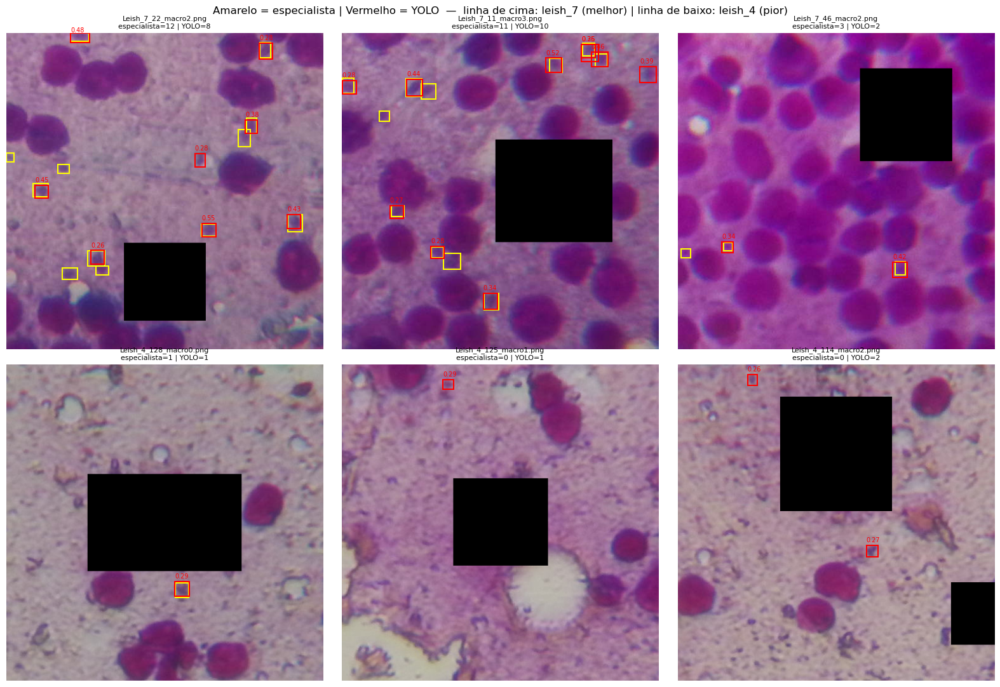

In [23]:
%matplotlib inline
melhor_lamina = resumo_lamina[('mAP50', 'mean')].idxmax()
pior_lamina = resumo_lamina[('mAP50', 'mean')].idxmin()
print(f"Melhor lâmina (mAP50): {melhor_lamina} | Pior lâmina (mAP50): {pior_lamina}")

cache_modelos = {}
def obter_modelo(n_fold):
    if n_fold not in cache_modelos:
        cache_modelos[n_fold] = YOLO(caminhos_best[n_fold])
    return cache_modelos[n_fold]

amostras_comparacao = []
random.seed(42)
for lamina in [melhor_lamina, pior_lamina]:
    n_fold = fold_para_lamina(lamina)
    pasta_img = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'images', 'test_lamina', lamina)
    pasta_lbl = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'labels', 'test_lamina', lamina)
    imagens = sorted(f for f in os.listdir(pasta_img) if f.endswith(extensao))
    escolhidas = random.sample(imagens, min(3, len(imagens)))
    for img_nome in escolhidas:
        amostras_comparacao.append((n_fold, lamina, pasta_img, pasta_lbl, img_nome))

fig, eixos = plt.subplots(2, 3, figsize=(16, 11))
for eixo, (n_fold, lamina, pasta_img, pasta_lbl, img_nome) in zip(eixos.ravel(), amostras_comparacao):
    modelo = obter_modelo(n_fold)
    nome_base = os.path.splitext(img_nome)[0]
    desenha_comparacao(eixo, os.path.join(pasta_img, img_nome), os.path.join(pasta_lbl, f"{nome_base}.txt"), modelo)

fig.suptitle(f"Amarelo = especialista | Vermelho = YOLO  —  linha de cima: {melhor_lamina} (melhor) | linha de baixo: {pior_lamina} (pior)")
plt.tight_layout()
plt.show()
